# Olist Brazilian E-commerce Marketplace: Data Mining and Predictive Analytics

**Assignment focus:** marketplace exploration, product combinations, seller segmentation, unusual-order detection and delivery prediction.

## Business context
Olist wants to understand purchasing patterns, improve seller performance and retention, identify orders that may need operational review, and improve delivery reliability. This notebook analyses the supplied Olist marketplace data and translates the results into practical recommendations.

## Research questions
1. What does the data reveal about the marketplace, and what preparation is required?
2. Which product categories are frequently purchased together, and how can Olist use these relationships to increase sales?
3. What seller segments can be identified from sales and service characteristics, and how should Olist serve and retain them?
4. Which orders appear unusual and deserve operational review?
5. Can Olist predict late delivery and the number of days between purchase and delivery?

## How to run
1. Put the Olist CSV files in one folder. The files may be in the repository root or a folder such as `data`.
2. Set `DATA_DIR` in the next cell.
3. Run the notebook from top to bottom.

The notebook uses common Olist file names. The reviews file is optional for the main analyses. The other eight files are required.

## 0. Imports and configuration

In [21]:
import os
import warnings
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_DIR = "."

def f(filename):
    return os.path.join(DATA_DIR, filename)

RANDOM_STATE = 42

## 1. Load the data

In [22]:
required_files = [
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv",
    "olist_customers_dataset.csv",
    "olist_sellers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    
]
missing_files = [name for name in required_files if not os.path.exists(f(name))]
if missing_files:
    raise FileNotFoundError(
        "These required files were not found in DATA_DIR:\n"
        + "\n".join(missing_files)
        + "\nCheck DATA_DIR and the CSV filenames."
    )

date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
orders = pd.read_csv(f("olist_orders_dataset.csv"), parse_dates=date_cols)
items = pd.read_csv(f("olist_order_items_dataset.csv"))
products = pd.read_csv(f("olist_products_dataset.csv"))
translations = pd.read_csv(f("product_category_name_translation.csv"))
customers = pd.read_csv(f("olist_customers_dataset.csv"))
sellers = pd.read_csv(f("olist_sellers_dataset.csv"))
geolocation = pd.read_csv(f("olist_geolocation_dataset.csv"))
payments = pd.read_csv(f("olist_order_payments_dataset.csv"))

reviews_path = f("olist_order_reviews_dataset.csv")
reviews = pd.read_csv(reviews_path) if os.path.exists(reviews_path) else None

datasets = {
    "orders": orders, "items": items, "products": products,
    "category translations": translations, "customers": customers,
    "sellers": sellers, "geolocation": geolocation, "payments": payments
}
if reviews is not None:
    datasets["reviews"] = reviews

overview = pd.DataFrame({
    "dataset": list(datasets.keys()),
    "rows": [len(x) for x in datasets.values()],
    "columns": [x.shape[1] for x in datasets.values()],
    "duplicate_rows": [x.duplicated().sum() for x in datasets.values()]
})
display(overview)

,dataset,rows,columns,duplicate_rows
0,orders,99441,8,0
1,items,112650,7,0
2,products,32951,9,0
3,category translations,71,2,0
4,customers,99441,5,0
5,sellers,3095,4,0
6,geolocation,1000163,5,261831
7,payments,103886,5,0
8,reviews,99224,7,0


## 2. Task 1 — Explore the data and prepare it

The Olist data is split across orders, order items, products, customers, sellers, payments and geographic reference tables. The tables are joined using their identifiers. The order-item table is the key transaction-level source: one order can contain several items and can involve more than one seller.

In [23]:
# Inspect structure and missing values for each table.
for name, frame in datasets.items():
    print(f"\n{name.upper()} — {frame.shape[0]:,} rows × {frame.shape[1]} columns")
    display(frame.head(3))
    missing = (frame.isna().mean() * 100).sort_values(ascending=False)
    display(missing[missing > 0].head(12).rename("missing_percent").to_frame())


ORDERS — 99,441 rows × 8 columns


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


,missing_percent
order_delivered_customer_date,2.981668
order_delivered_carrier_date,1.793023
order_approved_at,0.160899



ITEMS — 112,650 rows × 7 columns


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


,missing_percent


... (17 outputs left out)

,missing_percent



REVIEWS — 99,224 rows × 7 columns


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


,missing_percent
review_comment_title,88.341530
review_comment_message,58.702532


,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


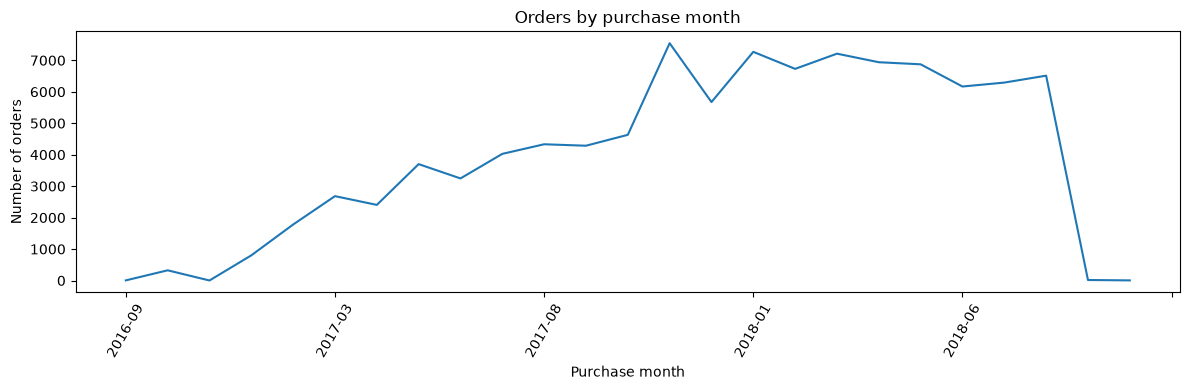

,count,mean,std,min,25%,50%,75%,max
price,112650.0,120.653739,183.633928,0.85,39.9,74.99,134.9,6735.0


,count,mean,std,min,25%,50%,75%,max
freight_value,112650.0,19.99032,15.806405,0.0,13.08,16.26,21.15,409.68


In [24]:
# Order status and date coverage.
display(orders["order_status"].value_counts(dropna=False).rename("orders").to_frame())

purchase_month = (
    orders.dropna(subset=["order_purchase_timestamp"])
    .assign(month=lambda x: x["order_purchase_timestamp"].dt.to_period("M").astype(str))
    .groupby("month").size()
)
plt.figure(figsize=(12, 4))
purchase_month.plot()
plt.title("Orders by purchase month")
plt.xlabel("Purchase month")
plt.ylabel("Number of orders")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Common descriptive statistics.
for col in ["price", "freight_value"]:
    if col in items.columns:
        display(items[col].describe().to_frame().T)

In [25]:
# Check key identifiers and duplicated records.
checks = {
    "duplicate order IDs in orders": orders["order_id"].duplicated().sum(),
    "duplicate product IDs in products": products["product_id"].duplicated().sum(),
    "duplicate seller IDs in sellers": sellers["seller_id"].duplicated().sum(),
    "duplicate customer IDs in customers": customers["customer_id"].duplicated().sum(),
    "duplicate order-item keys": items.duplicated(["order_id", "order_item_id"]).sum()
}
display(pd.Series(checks, name="count").to_frame())

,count
duplicate order IDs in orders,0
duplicate product IDs in products,0
duplicate seller IDs in sellers,0
duplicate customer IDs in customers,0
duplicate order-item keys,0


### Data preparation decisions

- **Date parsing:** order timestamps are parsed as dates so elapsed times and monthly trends can be calculated.
- **Product category translation:** Portuguese category names are translated to English where a translation is available. Untranslated categories are retained as `unknown` rather than dropping those transactions.
- **Geolocation:** multiple coordinate records can exist for a postal-code prefix. The median latitude and longitude provide one representative point per prefix.
- **Product dimensions:** zero weight or zero calculated volume is treated as missing because it is not a plausible usable measurement. Missing measurements are not interpreted as true zero.
- **Order-level aggregation:** item rows are aggregated to order level before modelling delivery outcomes. This prevents multi-item orders from being counted as separate delivery outcomes.
- **Delivery modelling population:** only delivered orders with known delivery dates and usable distance information can be used to train a model for actual delivery duration. This means results describe delivered orders, not cancelled or undelivered orders.
- **Extreme delivery durations:** durations above 90 days are excluded from the main duration model to reduce the influence of extreme records. This exclusion is reported as a modelling choice, not evidence that those orders were invalid.

The next cells create reusable joined data for the remaining tasks.

In [26]:
# Geolocation: one representative point per postal-code prefix.
geo = (
    geolocation.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
    .median()
)

# Add two category translations used in some versions of the Olist data.
extra_translations = pd.DataFrame({
    "product_category_name": [
        "pc_gamer",
        "portateis_cozinha_e_preparadores_de_alimentos"
    ],
    "product_category_name_english": [
        "pc_gamer",
        "portable_kitchen_food_preparers"
    ]
})
translations = pd.concat([translations, extra_translations], ignore_index=True)
translations = translations.drop_duplicates("product_category_name", keep="last")

products = products.merge(translations, how="left", on="product_category_name")
products["category"] = products["product_category_name_english"].fillna("unknown")
products["volume_cm3"] = (
    products["product_length_cm"] *
    products["product_height_cm"] *
    products["product_width_cm"]
)

for col in ["product_weight_g", "volume_cm3"]:
    products.loc[products[col] <= 0, col] = np.nan

# Calculate approximate straight-line distance between seller and customer postal-code centroids.
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (
        np.sin((lat2-lat1)/2)**2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2-lon1)/2)**2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(a))

item_data = (
    items.merge(
        products[["product_id", "category", "product_weight_g", "volume_cm3"]],
        on="product_id", how="left"
    )
    .merge(sellers, on="seller_id", how="left")
    .merge(orders, on="order_id", how="left")
    .merge(customers, on="customer_id", how="left")
)

item_data = item_data.join(
    geo.rename(columns={"geolocation_lat": "seller_lat", "geolocation_lng": "seller_lng"}),
    on="seller_zip_code_prefix"
)
item_data = item_data.join(
    geo.rename(columns={"geolocation_lat": "customer_lat", "geolocation_lng": "customer_lng"}),
    on="customer_zip_code_prefix"
)
item_data["distance_km"] = haversine(
    item_data["seller_lat"], item_data["seller_lng"],
    item_data["customer_lat"], item_data["customer_lng"]
)

# Payment data may have several rows per order; aggregate to one row per order.
payment_summary = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    installments=("payment_installments", "max"),
    payment_type=("payment_type", lambda x: x.mode().iloc[0] if not x.mode().empty else "unknown")
).reset_index()

# Create order-level transaction features.
order_items = item_data.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    n_sellers=("seller_id", "nunique"),
    sales_value=("price", "sum"),
    freight_value=("freight_value", "sum"),
    total_weight_g=("product_weight_g", "sum"),
    total_volume_cm3=("volume_cm3", "sum"),
    distance_km=("distance_km", "mean"),
    seller_state=("seller_state", "first"),
    first_category=("category", "first")
).reset_index()

order_data = (
    orders.merge(order_items, on="order_id", how="left")
    .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
    .merge(payment_summary, on="order_id", how="left")
)

order_data["delivery_days"] = (
    order_data["order_delivered_customer_date"] -
    order_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

order_data["estimated_days"] = (
    order_data["order_estimated_delivery_date"] -
    order_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

order_data["late"] = np.where(
    order_data["order_delivered_customer_date"].notna(),
    (
        order_data["order_delivered_customer_date"] >
        order_data["order_estimated_delivery_date"]
    ).astype(float),
    np.nan
)

print("Joined item-level rows:", f"{len(item_data):,}")
print("Order-level rows:", f"{len(order_data):,}")
display(order_data.head())

Joined item-level rows: 112,650
Order-level rows: 99,441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,n_items,n_sellers,sales_value,freight_value,total_weight_g,total_volume_cm3,distance_km,seller_state,first_category,customer_state,payment_value,installments,payment_type,delivery_days,estimated_days,late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1.0,1.0,29.99,8.72,500.0,1976.0,18.681711,SP,housewares,SP,38.71,1.0,voucher,8.436574,15.544063,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.0,1.0,118.70,22.76,400.0,4693.0,861.035367,SP,perfumery,BA,141.46,1.0,boleto,13.782037,19.137766,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1.0,1.0,159.90,19.22,420.0,9576.0,514.547140,SP,auto,GO,179.12,3.0,credit_card,9.394213,26.639711,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1.0,1.0,45.00,27.20,450.0,6000.0,1821.802656,MG,pet_shop,RN,72.20,1.0,credit_card,13.208750,26.188819,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1.0,1.0,19.90,8.72,250.0,11475.0,29.593095,SP,stationery,SP,28.62,1.0,credit_card,2.873877,12.112049,0.0


### Marketplace observations

Use the generated tables and charts to describe the marketplace. Avoid assuming that a pattern is causal: for example, a higher average freight charge may be associated with distance, package size or seller location, but this descriptive analysis alone cannot establish the cause.

,items_sold,orders,sellers,sales_value,average_item_price
category,,,,,
bed_bath_table,11115,9417,196,1036988.68,93.296327
health_beauty,9670,8836,492,1258681.34,130.163531
sports_leisure,8641,7720,481,988048.97,114.344285
computers_accessories,7827,6689,287,911954.32,116.513903
furniture_decor,8334,6449,370,729762.49,87.564494
housewares,6964,5884,468,632248.66,90.788148
watches_gifts,5991,5624,101,1205005.68,201.135984
telephony,4545,4199,149,323667.53,71.213978
auto,4235,3897,383,592720.11,139.957523


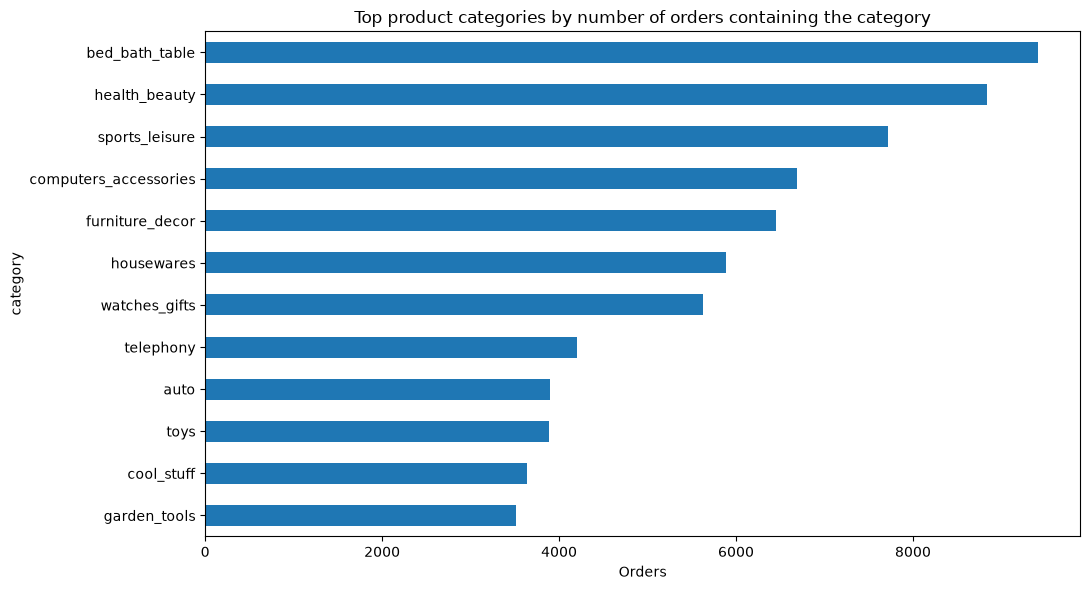

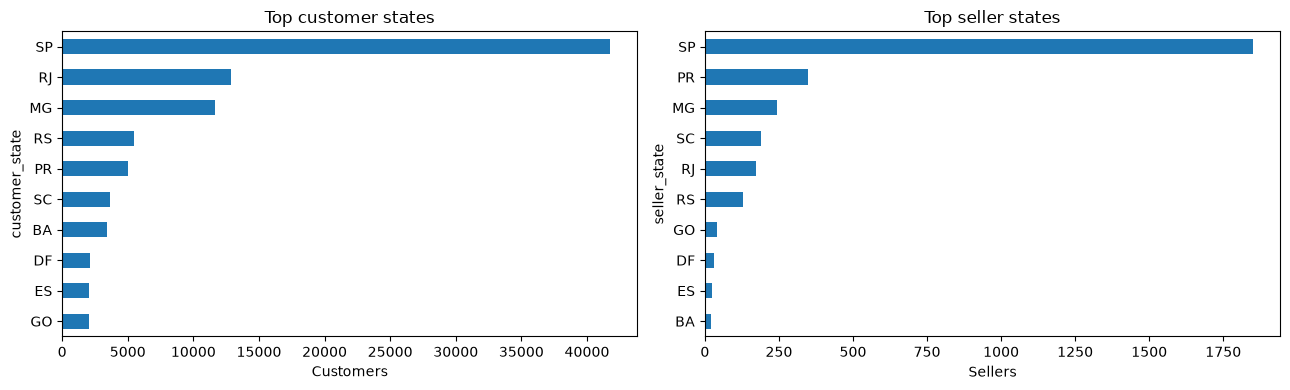

,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [27]:
# Category demand and sales value.
category_summary = (
    item_data.groupby("category")
    .agg(
        items_sold=("order_id", "size"),
        orders=("order_id", "nunique"),
        sellers=("seller_id", "nunique"),
        sales_value=("price", "sum"),
        average_item_price=("price", "mean")
    )
    .sort_values("orders", ascending=False)
)
display(category_summary.head(15))

plt.figure(figsize=(11, 6))
category_summary.head(12)["orders"].sort_values().plot(kind="barh")
plt.title("Top product categories by number of orders containing the category")
plt.xlabel("Orders")
plt.tight_layout()
plt.show()

# Customer and seller state distributions.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
customers["customer_state"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top customer states")
axes[0].set_xlabel("Customers")
sellers["seller_state"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top seller states")
axes[1].set_xlabel("Sellers")
plt.tight_layout()
plt.show()

# Delivery outcomes by order status.
delivery_status = order_data.groupby("order_status").size().sort_values(ascending=False)
display(delivery_status.rename("orders").to_frame())

## 3. Task 2 — Product categories frequently purchased together

### Method
Market basket analysis treats each order as a basket of product categories. Repeated occurrences of the same category within one order are counted once. For every pair of categories, the notebook calculates:

- **Support:** proportion of all eligible orders containing both categories.
- **Confidence (A → B):** proportion of orders containing A that also contain B.
- **Lift:** confidence divided by the overall proportion of orders containing B. A lift above 1 indicates that B occurs with A more often than would be expected if the categories were independent.

This implementation calculates category pairs directly and does not require an additional association-rule package. It focuses on pairs; it does not claim to discover all larger multi-category combinations.

In [28]:
# One set of categories per order; ignore missing order IDs and blank categories.
basket_rows = item_data.dropna(subset=["order_id", "category"]).copy()
basket_rows["category"] = basket_rows["category"].replace("", "unknown")
basket = basket_rows.groupby("order_id")["category"].apply(lambda x: sorted(set(x)))

n_baskets = len(basket)
category_counts = {}
pair_counts = {}

for categories in basket:
    for cat in categories:
        category_counts[cat] = category_counts.get(cat, 0) + 1
    for a, b in combinations(categories, 2):
        pair_counts[(a, b)] = pair_counts.get((a, b), 0) + 1

min_support = 0.001  # configurable minimum pair support
rules = []
for (a, b), count_ab in pair_counts.items():
    support = count_ab / n_baskets
    if support < min_support:
        continue
    support_a = category_counts[a] / n_baskets
    support_b = category_counts[b] / n_baskets
    rules.append({
        "category_A": a,
        "category_B": b,
        "orders_together": count_ab,
        "support": support,
        "confidence_A_to_B": count_ab / category_counts[a],
        "confidence_B_to_A": count_ab / category_counts[b],
        "lift": support / (support_a * support_b)
    })

pair_rules = pd.DataFrame(rules)
if pair_rules.empty:
    print("No category pairs met the current minimum support. Lower min_support to explore more pairs.")
else:
    pair_rules = pair_rules.sort_values(
        ["lift", "orders_together"], ascending=[False, False]
    )
    display(pair_rules.head(20))

No category pairs met the current minimum support. Lower min_support to explore more pairs.


In [29]:
if not pair_rules.empty:
    # Show pairs with both a meaningful order count and lift above 1.
    useful_pairs = pair_rules[
        (pair_rules["orders_together"] >= 20) & (pair_rules["lift"] > 1)
    ].head(12).copy()

    if useful_pairs.empty:
        print("No pairs met the additional display threshold of 20 orders and lift > 1.")
    else:
        useful_pairs["pair"] = useful_pairs["category_A"] + " + " + useful_pairs["category_B"]
        plt.figure(figsize=(10, 6))
        useful_pairs.sort_values("lift").plot(
            x="pair", y="lift", kind="barh", legend=False, figsize=(10, 6)
        )
        plt.title("Frequently associated category pairs (lift > 1)")
        plt.xlabel("Lift")
        plt.ylabel("Category pair")
        plt.tight_layout()
        plt.show()

### Business interpretation and recommendations

Olist can use category relationships with sufficient support and lift to:

1. **Recommend complementary products:** display category B when a customer views or adds category A.
2. **Create bundles:** test discounted combinations where the pair occurs frequently and has positive commercial value.
3. **Improve campaign targeting:** send relevant cross-selling messages rather than generic promotions.
4. **Plan merchandising:** use observed combinations to inform product discovery and category navigation.

A high lift based on very few orders can be unstable. Olist should consider both lift and the number of orders together, then test recommendations through controlled experiments before assuming they increase revenue.

## 4. Task 3 — Seller segmentation by sales and service characteristics

### Method
Seller performance is measured using order-item records. The features include sales value, number of orders, number of items, average item price, average freight, average delivery duration, late-delivery rate and review score where available.

K-Means clustering is applied to standardised seller metrics. Standardisation is important because sales values and rates are measured on different scales. Seller groups are descriptive profiles, not permanent labels or proof of seller quality.

In [30]:
# Seller sales and order volume.
seller_metrics = item_data.groupby("seller_id").agg(
    sales_value=("price", "sum"),
    item_count=("order_item_id", "count"),
    order_count=("order_id", "nunique"),
    average_item_price=("price", "mean"),
    average_freight=("freight_value", "mean"),
    average_distance_km=("distance_km", "mean")
).reset_index()

# Seller-level service measures from orders.
seller_order_rows = item_data[
    ["seller_id", "order_id", "order_purchase_timestamp",
     "order_delivered_customer_date", "order_estimated_delivery_date"]
].drop_duplicates(["seller_id", "order_id"]).copy()

seller_order_rows["delivery_days"] = (
    seller_order_rows["order_delivered_customer_date"] -
    seller_order_rows["order_purchase_timestamp"]
).dt.total_seconds() / 86400

seller_order_rows["late_flag"] = np.where(
    seller_order_rows["order_delivered_customer_date"].notna(),
    (seller_order_rows["order_delivered_customer_date"] >
     seller_order_rows["order_estimated_delivery_date"]).astype(float),
    np.nan
)

service_metrics = seller_order_rows.groupby("seller_id").agg(
    average_delivery_days=("delivery_days", "mean"),
    late_rate=("late_flag", "mean"),
    delivered_orders=("delivery_days", "count")
).reset_index()

seller_profile = seller_metrics.merge(service_metrics, on="seller_id", how="left")

# Optional seller review score from the reviews table.
if reviews is not None and "review_score" in reviews.columns:
    order_seller = item_data[["order_id", "seller_id"]].drop_duplicates()
    review_seller = (
        reviews.merge(order_seller, on="order_id", how="inner")
        .groupby("seller_id")["review_score"].mean()
        .rename("average_review_score").reset_index()
    )
    seller_profile = seller_profile.merge(review_seller, on="seller_id", how="left")

display(seller_profile.describe(include="all").T)
display(seller_profile.head())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
seller_id,3095,3095,0015a82c2db000af6aaaf3ae2ecb0532,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sales_value,3095.0,NaN,NaN,NaN,4391.484233,13921.997192,3.5,208.85,821.48,3280.83,229472.63
item_count,3095.0,NaN,NaN,NaN,36.397415,119.193461,1.0,2.0,8.0,24.0,2033.0
order_count,3095.0,NaN,NaN,NaN,32.313409,105.139763,1.0,2.0,6.0,21.5,1854.0
average_item_price,3095.0,NaN,NaN,NaN,176.325102,322.145495,3.5,52.183608,95.465385,173.992857,6729.0
average_freight,3095.0,NaN,NaN,NaN,23.380116,18.957766,1.2,14.74,18.23,24.368333,308.336667
average_distance_km,3088.0,NaN,NaN,NaN,612.707812,394.11126,1.135905,376.306847,549.266954,758.089177,2798.84369
average_delivery_days,2970.0,NaN,NaN,NaN,12.215042,7.155681,1.214178,8.411204,11.156808,14.236876,189.86316
late_rate,2970.0,NaN,NaN,NaN,0.084212,0.168753,0.0,0.0,0.0,0.101308,1.0
delivered_orders,3095.0,NaN,NaN,NaN,31.604847,103.464076,0.0,2.0,6.0,21.0,1819.0


,seller_id,sales_value,item_count,order_count,average_item_price,average_freight,average_distance_km,average_delivery_days,late_rate,delivered_orders,average_review_score
0,0015a82c2db000af6aaaf3ae2ecb0532,2685.00,3,3,895.000000,21.020000,606.589740,10.793885,0.000000,3,3.666667
1,001cca7ae9ae17fb1caed9dfb1094831,25080.03,239,200,104.937364,37.046611,811.016408,13.405805,0.066667,195,3.984772
2,001e6ad469a905060d959994f1b41e4f,250.00,1,1,250.000000,17.940000,394.481094,NaN,NaN,0,1.000000
3,002100f778ceb8431b7a1020ff7ab48f,1234.50,55,51,22.445455,14.430182,523.163510,16.386809,0.180000,50,3.903846
4,003554e2dce176b5555353e4f3555ac8,120.00,1,1,120.000000,19.380000,936.393081,4.646806,0.000000,1,5.000000


In [31]:
# Cluster sellers with enough activity to make their profiles more stable.
cluster_features = [
    "sales_value", "order_count", "average_item_price",
    "average_freight", "average_delivery_days", "late_rate"
]
if "average_review_score" in seller_profile.columns:
    cluster_features.append("average_review_score")

seller_cluster_data = seller_profile.copy()
seller_cluster_data = seller_cluster_data[
    seller_cluster_data["order_count"].fillna(0) >= 5
].copy()

# Log-transform highly skewed sales and order counts.
seller_cluster_data["log_sales"] = np.log1p(seller_cluster_data["sales_value"].clip(lower=0))
seller_cluster_data["log_orders"] = np.log1p(seller_cluster_data["order_count"].clip(lower=0))
model_features = [
    "log_sales", "log_orders", "average_item_price",
    "average_freight", "average_delivery_days", "late_rate"
]
if "average_review_score" in seller_cluster_data.columns:
    model_features.append("average_review_score")

# Impute missing service metrics with the median, then scale.
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_imp = imputer.fit_transform(seller_cluster_data[model_features])
X_scaled = scaler.fit_transform(X_imp)

n_clusters = min(4, max(2, len(seller_cluster_data) // 20))
if len(seller_cluster_data) >= n_clusters:
    kmeans = KMeans(n_clusters=n_clusters, random_state=RANDOM_STATE, n_init=10)
    seller_cluster_data["seller_segment"] = kmeans.fit_predict(X_scaled)
else:
    raise ValueError("There are too few active sellers for clustering.")

seller_profile = seller_profile.merge(
    seller_cluster_data[["seller_id", "seller_segment"]],
    on="seller_id", how="left"
)

segment_summary = seller_cluster_data.groupby("seller_segment").agg(
    sellers=("seller_id", "count"),
    median_sales=("sales_value", "median"),
    median_orders=("order_count", "median"),
    median_average_delivery_days=("average_delivery_days", "median"),
    median_late_rate=("late_rate", "median"),
    median_freight=("average_freight", "median")
)
if "average_review_score" in seller_cluster_data.columns:
    segment_summary["median_review_score"] = (
        seller_cluster_data.groupby("seller_segment")["average_review_score"].median()
    )
display(segment_summary.round(2))

,sellers,median_sales,median_orders,median_average_delivery_days,median_late_rate,median_freight,median_review_score
seller_segment,,,,,,,
0,72,8745.12,11.0,13.79,0.07,63.91,4.20
1,620,8154.55,68.0,12.27,0.07,18.60,4.14
2,812,1040.00,10.0,9.67,0.00,17.35,4.36
3,290,1498.47,11.0,16.81,0.20,19.36,3.64


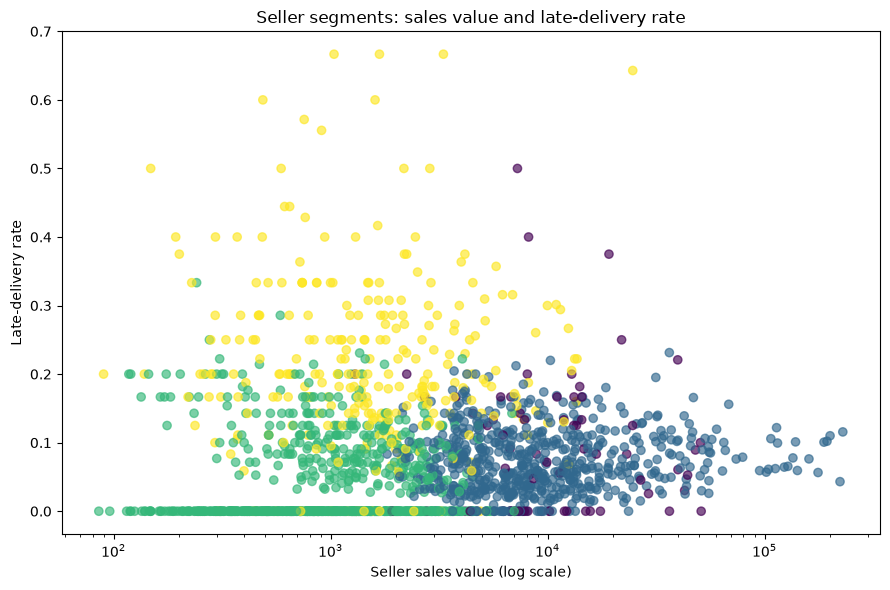

,median_sales,median_orders,median_late_rate
seller_segment,,,
0,8745.125,11.0,0.066964
1,8154.550,68.0,0.066667
2,1040.000,10.0,0.000000
3,1498.470,11.0,0.200000


In [32]:
plt.figure(figsize=(9, 6))
plt.scatter(
    seller_cluster_data["sales_value"],
    seller_cluster_data["late_rate"],
    c=seller_cluster_data["seller_segment"],
    alpha=0.65
)
plt.xscale("log")
plt.xlabel("Seller sales value (log scale)")
plt.ylabel("Late-delivery rate")
plt.title("Seller segments: sales value and late-delivery rate")
plt.tight_layout()
plt.show()

# Segment profile chart using median values.
segment_plot = segment_summary[["median_sales", "median_orders", "median_late_rate"]].copy()
display(segment_plot)

### How Olist can serve and retain each segment

Use the segment profile table to assign practical support. The cluster numbers are arbitrary, so interpret each segment using its measured characteristics rather than assuming that cluster 0 is always the best.

- **High sales, strong service:** recognise and retain these strategic sellers with account management, early access to marketplace campaigns and performance-based incentives.
- **High sales, weaker service:** prioritise operational coaching, fulfilment monitoring and delivery improvement plans because service problems can affect many customers.
- **Lower sales, strong service:** help these sellers grow through visibility, onboarding support, product discovery and targeted promotions.
- **Lower sales, weaker service:** provide basic training, clear service standards and time-bound improvement support. Review continued marketplace participation if problems persist.

Olist should validate these profiles over time and avoid penalising sellers based on a small number of orders. Seller location, product type and shipping arrangements may influence delivery performance.

## 5. Task 4 — Identify unusual orders for operational review

### Method
Anomaly detection is used to prioritise orders for investigation, not to declare fraud. The analysis combines interpretable business rules with Isolation Forest, an unsupervised algorithm that identifies combinations of features that are relatively unusual.

The features include order value, freight, number of items, number of sellers, package weight and volume, seller-to-customer distance, approval time and delivery duration. Delivery duration is only available after delivery; therefore, it is useful for retrospective operational review, not for an alert at the moment of purchase.

In [33]:
anomaly_data = order_data.copy()
anomaly_data["approval_hours"] = (
    anomaly_data["order_approved_at"] -
    anomaly_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600

anomaly_features = [
    "sales_value", "freight_value", "n_items", "n_sellers",
    "total_weight_g", "total_volume_cm3", "distance_km",
    "approval_hours", "delivery_days"
]
available_features = [x for x in anomaly_features if x in anomaly_data.columns]

# Keep orders with at least some usable transaction information.
anomaly_data = anomaly_data.dropna(subset=["sales_value", "freight_value"]).copy()
X_anom = anomaly_data[available_features].replace([np.inf, -np.inf], np.nan)

# Median imputation and log transforms reduce the influence of extreme positive skew.
X_anom = X_anom.apply(lambda col: col.fillna(col.median()))
for col in ["sales_value", "freight_value", "n_items", "n_sellers",
            "total_weight_g", "total_volume_cm3", "distance_km"]:
    if col in X_anom.columns:
        X_anom[col] = np.log1p(X_anom[col].clip(lower=0))

iso = IsolationForest(
    n_estimators=250, contamination=0.02,
    random_state=RANDOM_STATE
)
anomaly_data["isolation_flag"] = iso.fit_predict(X_anom)
anomaly_data["anomaly_score"] = -iso.score_samples(X_anom)
anomaly_data["unusual_order"] = anomaly_data["isolation_flag"].eq(-1)

# Add transparent flags to help explain why an order was selected.
def upper_iqr_flag(series, multiplier=3.0):
    q1, q3 = series.quantile([0.25, 0.75])
    return series > (q3 + multiplier * (q3 - q1))

anomaly_data["high_value_flag"] = upper_iqr_flag(anomaly_data["sales_value"])
anomaly_data["high_freight_flag"] = upper_iqr_flag(anomaly_data["freight_value"])
anomaly_data["many_items_flag"] = upper_iqr_flag(anomaly_data["n_items"])
anomaly_data["long_delivery_flag"] = anomaly_data["delivery_days"] > 30

reason_cols = [
    "high_value_flag", "high_freight_flag",
    "many_items_flag", "long_delivery_flag"
]
anomaly_data["rule_flag_count"] = anomaly_data[reason_cols].sum(axis=1)

# Prioritise model anomalies with at least one interpretable flag, while retaining the score.
review_queue = anomaly_data[
    anomaly_data["unusual_order"] | (anomaly_data["rule_flag_count"] > 0)
].copy()
review_queue = review_queue.sort_values(
    ["rule_flag_count", "anomaly_score"], ascending=False
)

review_columns = [
    "order_id", "order_status", "sales_value", "freight_value",
    "n_items", "n_sellers", "distance_km", "delivery_days",
    "anomaly_score", "rule_flag_count"
]
display(review_queue[review_columns].head(25))
print("Orders selected for review:", f"{len(review_queue):,}")

,order_id,order_status,sales_value,freight_value,n_items,n_sellers,distance_km,delivery_days,anomaly_score,rule_flag_count
16335,71dab1155600756af6de79de92e712e3,delivered,1361.89,626.64,11.0,1.0,1664.705987,39.018275,0.716049,4
8287,1a9543c90f188e2e4fb14327ad4a9c9b,delivered,479.94,182.40,6.0,1.0,366.708862,45.191343,0.709996,4
25386,53cbc02ffe278ca84b6f4920d9d3ecd5,delivered,1995.00,281.10,5.0,1.0,140.589237,33.722766,0.708298,4
88772,cfed507ac357129f750f05a0d7d71b15,delivered,1380.00,711.33,3.0,1.0,1546.986407,39.549676,0.706787,4
86021,5448a97fc343f6f23807effd01938241,delivered,749.70,126.80,5.0,1.0,215.858953,42.304074,0.705953,4
63885,299372a2c0a08ae166a4dd2a2467dfec,delivered,582.00,322.80,3.0,1.0,2103.305931,33.228495,0.702300,4
21438,a45d988c5f5764f548ae6fa14a8ee773,delivered,899.95,323.75,5.0,1.0,2340.234127,36.440301,0.699260,4
80367,05728fca024954ba1ce915ad5c94991f,delivered,784.70,239.50,5.0,1.0,802.977750,31.263681,0.698061,4
52144,c6d26341bec0769b3ccfa232c63b3675,delivered,509.70,228.15,3.0,1.0,2346.391395,39.352315,0.697232,4
74966,a6a5d5673d42186a8b8b94ad29b59897,delivered,899.80,347.56,2.0,1.0,816.591815,66.695231,0.690830,4


Orders selected for review: 19,135


,orders
Isolation Forest anomalies,1974
Unusually high order value,4095
Unusually high freight,5023
Unusually many items,9803
Delivery over 30 days,4553


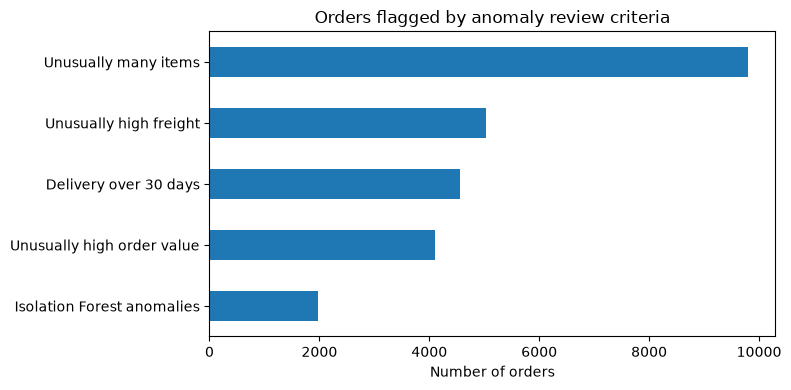

In [34]:
# Summarise why the highest-priority orders were flagged.
flag_summary = pd.Series({
    "Isolation Forest anomalies": anomaly_data["unusual_order"].sum(),
    "Unusually high order value": anomaly_data["high_value_flag"].sum(),
    "Unusually high freight": anomaly_data["high_freight_flag"].sum(),
    "Unusually many items": anomaly_data["many_items_flag"].sum(),
    "Delivery over 30 days": anomaly_data["long_delivery_flag"].sum()
}, name="orders")
display(flag_summary.to_frame())

plt.figure(figsize=(8, 4))
flag_summary.sort_values().plot(kind="barh")
plt.title("Orders flagged by anomaly review criteria")
plt.xlabel("Number of orders")
plt.tight_layout()
plt.show()

### Operational recommendations

Olist should review flagged orders in a risk-based queue:

- Check unusually high order values against payment and seller records.
- Check high freight charges against distance, package dimensions and carrier arrangements.
- Check unusually large baskets for picking, packing and stock-handling issues.
- Investigate long delivery times for carrier delays, incorrect addresses or seller dispatch problems.
- Compare the order history and customer/seller records before taking action.

An anomaly is not proof of misconduct. The 2% Isolation Forest contamination setting is a chosen review capacity assumption, not a measured fraud rate. Olist should tune it to available investigation resources and monitor false positives.

## 6. Task 5 — Predict late delivery and delivery duration

### Prediction design and limitations
Two supervised learning tasks are developed:

1. **Late-delivery classification:** predict whether the delivered order arrived after its estimated delivery date.
2. **Delivery-time regression:** predict the number of days from purchase to customer delivery.

The models are trained on delivered orders with known delivery dates and a known approximate seller-customer distance. Cancelled and undelivered orders cannot provide an observed delivery duration and are excluded.

The split is chronological: orders purchased before 1 April 2018 are used for training and orders purchased on or after that date are used for testing. This better reflects prediction on future orders than a random split.

**Prediction timing:** this version uses approval time and other order information, so it represents a prediction made after the order is approved and the relevant order details are available. It is not a prediction made at the instant the customer clicks “buy”. The estimated delivery interval is included because it is part of the information available in the order record; in a live system, confirm that this estimate is available at the intended prediction time.

In [35]:
delivery = order_data[
    (order_data["order_status"] == "delivered")
    & order_data["order_delivered_customer_date"].notna()
    & order_data["distance_km"].notna()
    & order_data["late"].notna()
].copy()

delivery = delivery[
    delivery["delivery_days"].between(0, 90, inclusive="both")
].copy()

purchase_time = delivery["order_purchase_timestamp"]
delivery["approval_hours"] = (
    delivery["order_approved_at"] - purchase_time
).dt.total_seconds() / 3600
delivery["approval_hours"] = delivery["approval_hours"].clip(0, 200)

delivery["month"] = purchase_time.dt.month
delivery["day_of_week"] = purchase_time.dt.dayofweek
delivery["purchase_hour"] = purchase_time.dt.hour
delivery["same_state"] = (
    delivery["customer_state"] == delivery["seller_state"]
).astype(int)
delivery["freight_ratio"] = (
    delivery["freight_value"] /
    delivery["sales_value"].clip(lower=1)
)

# Fill missing categorical values and use pandas category dtype for HistGradientBoosting.
categorical_features = [
    "customer_state", "seller_state", "first_category", "payment_type"
]
numeric_features = [
    "sales_value", "freight_value", "freight_ratio",
    "total_weight_g", "total_volume_cm3", "n_items", "n_sellers",
    "distance_km", "estimated_days", "approval_hours",
    "month", "day_of_week", "purchase_hour", "same_state", "installments"
]

for col in categorical_features:
    delivery[col] = delivery[col].fillna("unknown").astype("category")

for col in numeric_features:
    delivery[col] = pd.to_numeric(delivery[col], errors="coerce")

features = numeric_features + categorical_features

cutoff = pd.Timestamp("2018-04-01")
train = delivery[delivery["order_purchase_timestamp"] < cutoff].copy()
test = delivery[delivery["order_purchase_timestamp"] >= cutoff].copy()

if train.empty or test.empty:
    raise ValueError(
        "The time-based split produced an empty train or test set. "
        "Check the dataset date range and adjust cutoff."
    )
if train["late"].nunique() < 2:
    raise ValueError("Training data contains only one late-delivery class; classification cannot be fitted.")

print(f"Training orders: {len(train):,}")
print(f"Testing orders:  {len(test):,}")
print(f"Late rate — train: {train['late'].mean():.1%}")
print(f"Late rate — test:  {test['late'].mean():.1%}")

Training orders: 63,918
Testing orders:  31,999
Late rate — train: 9.0%
Late rate — test:  6.0%


### 6.1 Late-delivery classification

ROC-AUC: 0.704
PR-AUC: 0.128

Classification report:
              precision    recall  f1-score   support

           0       0.95      0.86      0.90     30081
           1       0.14      0.36      0.20      1918

    accuracy                           0.83     31999
   macro avg       0.55      0.61      0.55     31999
weighted avg       0.91      0.83      0.86     31999



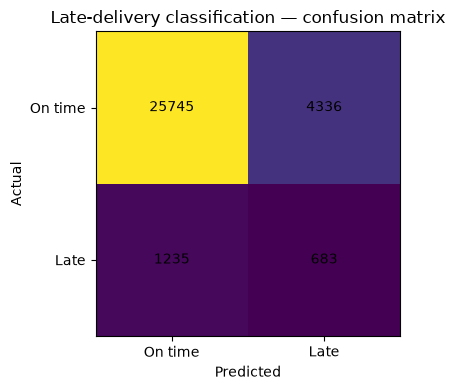

,threshold,orders_flagged_percent,precision,recall,f1
0,0.3,55.767,0.087,0.813,0.158
1,0.4,32.723,0.109,0.595,0.184
2,0.5,15.685,0.136,0.356,0.197
3,0.6,4.831,0.187,0.151,0.167
4,0.7,0.538,0.215,0.019,0.035


In [36]:
classifier = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=20,
    categorical_features="from_dtype",
    class_weight="balanced",
    random_state=RANDOM_STATE
)
classifier.fit(train[features], train["late"].astype(int))

late_probability = classifier.predict_proba(test[features])[:, 1]
late_prediction = (late_probability >= 0.5).astype(int)

print("ROC-AUC:", round(roc_auc_score(test["late"].astype(int), late_probability), 3))
print("PR-AUC:", round(average_precision_score(test["late"].astype(int), late_probability), 3))
print("\nClassification report:")
print(classification_report(test["late"].astype(int), late_prediction, zero_division=0))

cm = confusion_matrix(test["late"].astype(int), late_prediction)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Late-delivery classification — confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["On time", "Late"])
plt.yticks([0, 1], ["On time", "Late"])
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

# Thresholds represent different operational alert workloads.
threshold_rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    flagged = late_probability >= threshold
    threshold_rows.append({
        "threshold": threshold,
        "orders_flagged_percent": flagged.mean() * 100,
        "precision": precision_score(test["late"].astype(int), flagged, zero_division=0),
        "recall": recall_score(test["late"].astype(int), flagged, zero_division=0),
        "f1": f1_score(test["late"].astype(int), flagged, zero_division=0)
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

**Interpretation:** ROC-AUC measures how well the model ranks late orders above on-time orders across thresholds. PR-AUC is useful when late orders are less common than on-time orders. Precision indicates the proportion of alerts that were actually late; recall indicates the proportion of late orders that the model identified. Olist should choose an alert threshold based on the cost of reviewing an order and the cost of a late delivery, rather than automatically choosing 0.5.

### 6.2 Delivery-time regression

Model MAE: 3.88 days
Model RMSE: 5.73 days
Model R²: 0.323
Training median baseline MAE: 5.52 days
Olist estimated-date baseline MAE: 12.77 days
Predictions within 3 days: 51.4%
Olist estimate within 3 days: 9.2%


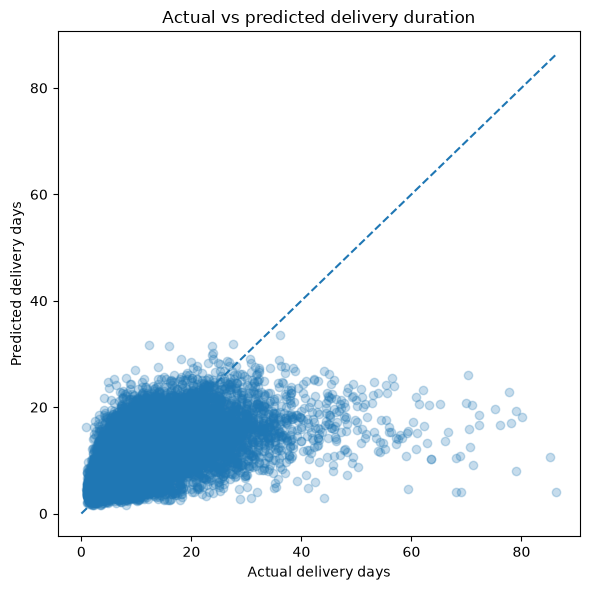

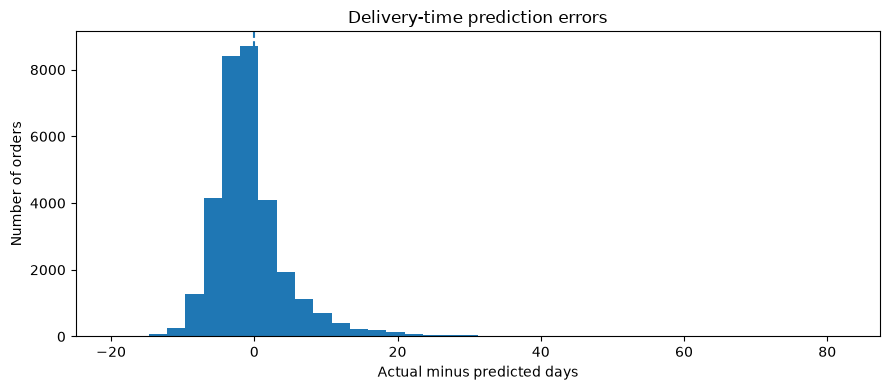

In [37]:
regressor = HistGradientBoostingRegressor(
    max_iter=400,
    learning_rate=0.05,
    max_leaf_nodes=20,
    categorical_features="from_dtype",
    loss="absolute_error",
    random_state=RANDOM_STATE
)
regressor.fit(train[features], train["delivery_days"])
predicted_days = regressor.predict(test[features])

model_mae = mean_absolute_error(test["delivery_days"], predicted_days)
model_rmse = mean_squared_error(test["delivery_days"], predicted_days) ** 0.5
model_r2 = r2_score(test["delivery_days"], predicted_days)

# Baselines: training-set median and Olist's estimated purchase-to-delivery interval.
median_baseline = np.full(len(test), train["delivery_days"].median())
promise_baseline = test["estimated_days"]

print(f"Model MAE: {model_mae:.2f} days")
print(f"Model RMSE: {model_rmse:.2f} days")
print(f"Model R²: {model_r2:.3f}")
print(f"Training median baseline MAE: {mean_absolute_error(test['delivery_days'], median_baseline):.2f} days")
print(f"Olist estimated-date baseline MAE: {mean_absolute_error(test['delivery_days'], promise_baseline):.2f} days")
print(f"Predictions within 3 days: {(np.abs(test['delivery_days'] - predicted_days) <= 3).mean():.1%}")
print(f"Olist estimate within 3 days: {(np.abs(test['delivery_days'] - promise_baseline) <= 3).mean():.1%}")

plt.figure(figsize=(6, 6))
plt.scatter(test["delivery_days"], predicted_days, alpha=0.25)
limit = max(test["delivery_days"].max(), np.nanmax(predicted_days))
plt.plot([0, limit], [0, limit], linestyle="--")
plt.xlabel("Actual delivery days")
plt.ylabel("Predicted delivery days")
plt.title("Actual vs predicted delivery duration")
plt.tight_layout()
plt.show()

residuals = test["delivery_days"].to_numpy() - predicted_days
plt.figure(figsize=(9, 4))
plt.hist(residuals, bins=40)
plt.axvline(0, linestyle="--")
plt.title("Delivery-time prediction errors")
plt.xlabel("Actual minus predicted days")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

### Model comparison and practical use

- Use the **late-delivery classifier** to rank orders for proactive monitoring after approval.
- Use the **delivery-time regressor** to estimate expected delivery duration and identify orders likely to exceed the promised interval.
- Compare the model with both the training-median baseline and Olist's estimated delivery interval. A model is useful only if it provides a meaningful improvement over these simple alternatives.
- Monitor performance over time because carrier conditions, seller behaviour, seasonality and marketplace operations can change.

This notebook uses HistGradientBoosting models as a practical starting point. Further work could compare them with logistic regression, random forests and other algorithms, tune hyperparameters using time-aware validation, and calibrate classification probabilities.

## 7. Overall business recommendations

1. **Increase sales through relevant cross-selling.** Use product category pairs with adequate order support and lift to create recommendations and bundle experiments.
2. **Retain sellers through differentiated support.** Recognise high-sales/high-service sellers, help growing sellers gain visibility, and provide targeted improvement plans to sellers with service problems.
3. **Prioritise operational investigations.** Combine anomaly scores with transparent flags such as unusually high freight, order value, item count or delivery duration. Treat flags as leads for review, not proof of wrongdoing.
4. **Improve delivery reliability.** Use late-delivery probabilities to prioritise proactive contact with sellers and carriers. Use predicted delivery duration to improve customer communication and operational planning.
5. **Evaluate business impact.** Test recommendations and interventions using controlled experiments or before-and-after monitoring. Track conversion, average order value, seller retention, late-delivery rate and customer satisfaction.

## 8. Limitations

- The data represents historical marketplace activity; relationships may change over time.
- Association rules identify co-purchase patterns, not causal product relationships.
- Seller clusters depend on the selected features, scaling, activity threshold and number of clusters. Cluster labels are descriptive.
- Anomaly detection identifies unusual records, not confirmed fraud or misconduct.
- Delivery models are trained only on delivered orders with known outcomes. They do not directly predict whether an order will be cancelled or never delivered.
- The 90-day delivery-duration filter removes extreme observations from the regression population and may reduce representation of severe delivery failures.
- Straight-line distance calculated from postal-code centroids is only an approximation of actual transport distance.
- The model's usefulness depends on whether each feature is genuinely available at the chosen prediction time. Approval-time features mean this notebook's prediction point is after approval.
- Historical patterns do not establish that a particular intervention will cause sales or delivery performance to improve.

## 9. Conclusion

This project analyses the Olist marketplace from five operational perspectives: data quality and marketplace structure, products purchased together, seller performance, unusual orders and delivery prediction. The analyses provide a basis for more relevant cross-selling, differentiated seller support and risk-based operational review. The classification and regression models offer ways to prioritise potentially late orders and estimate delivery duration. Olist should validate these findings with operational teams and monitor their impact before deploying recommendations or model alerts in production.

## Appendix — Optional checks before submission

Run this final cell to confirm that the principal analysis outputs were created.

In [38]:
checks = {
    "Loaded orders": len(orders),
    "Loaded order items": len(items),
    "Prepared order-level records": len(order_data),
    "Orders in market-basket analysis": n_baskets,
    "Seller profiles": len(seller_profile),
    "Sellers assigned to a cluster": seller_profile["seller_segment"].notna().sum(),
    "Orders in anomaly review queue": len(review_queue),
    "Delivery-model training records": len(train),
    "Delivery-model testing records": len(test),
}
display(pd.Series(checks, name="count").to_frame())
print("Notebook workflow completed. Review all tables, plots and printed metrics before submission.")

,count
Loaded orders,99441
Loaded order items,112650
Prepared order-level records,99441
Orders in market-basket analysis,98666
Seller profiles,3095
Sellers assigned to a cluster,1794
Orders in anomaly review queue,19135
Delivery-model training records,63918
Delivery-model testing records,31999


Notebook workflow completed. Review all tables, plots and printed metrics before submission.
